# Análisis de la señal: $x(t) = \displaystyle \sum_{i=1}^n b_i \sin \left (\frac{2\pi}{T_i} t\right)$ o, $x(t) = \displaystyle \sum_{i=1}^n a_i \cos\left(\frac{2\pi}{T_i} t\right)$

#### Ejemplo. Determinar período y frecuencia de la señal, y las armónicas presentes de la suma:

### $x(t) =  5 \sin(\frac{\pi t}{3}) -2 \sin(\frac{2\pi t}{4}) + 4\sin(\frac{\pi t}{9})$

#### Ordenemos (si no lo está) las componentes de menor a mayor período, y expresemos los ángulos en la forma: $\displaystyle \frac{2\pi}{T_i} t$, a fin de evidenciar el periódo $T$ de la señal y tipo de armónica presente (multiplique y divida por enteros apropiados)

### $x(t) =  -4 \sin(\frac{2\pi}{5}t) +3 \sin(\frac{2\pi}{4}t) + 5\sin(\frac{2\pi}{7}t) $

#### Ingresemos sus períodos y amplitudes presentes en listas o vectores.

In [1]:
periodos = [4, 5, 7]          # ingrese los períodos de menor a mayor
coeficientes = [3, -4, 5]     # ingrese los coeficientes según períodos correspondientes

#### Vemos que la señal contiene componentes con perídos $3, 4$ y $6$ seg. Para determinar el período $T$ de la señal, determinemos el MINIMO COMUN MÚLTIPLO, de los perídos de cada una de sus componentes. Usemos los códigos siguientes (o bien encuentrelos por inspección):

In [2]:
from pylab import gcd
lcm = periodos[0]
for i in periodos[1:]:
  lcm = lcm*i//gcd(lcm, i)
T = lcm
print('El periodo es: %d' % T)

# Code contributed by Ananay Mital

El periodo es: 140


#### En este caso el perido de la señal es $T = 12$ seg y su frecuencia es $f = 1/12$ cps o Hz. 

####  Construyamos una tabla que incluya: amplitudes, frecuencias, períodos y armónica correspondiente de cada componente de la señal dada. Para derminar el tipo de armónica de cada componente, calculemos los cocientes, período de la señal $T$ entre el período de cada componente $T_i$ 

In [3]:
print ('Amplitud  frecuencia Hz  período sg  armónica')
amplitudes = [abs(k) for k in coeficientes] 
frecuencia = [1./k for k in periodos]
armonicas = [T/k for k in periodos]
for i in range(len(periodos)):
    print ('%5.1f %14.3f %10d %10d' %(amplitudes[i], frecuencia[i], periodos[i], armonicas[i]))

Amplitud  frecuencia Hz  período sg  armónica
  3.0          0.250          4         35
  4.0          0.200          5         28
  5.0          0.143          7         20


#### De aquí vemos que en la señal $x(t)$, la componente con perido $3$ seg y amplitud $|-4| =4$ es la cuarta armónica, la componente con período $4$ seg con amplitud $3$ es la tercera armónica, y la componente con período $6$  seg con amplitud $0.7$  es la segunda armónica. El período de la señal es $T = 12$ seg, y su frecuencia es $f = 1/12$ cps o Hz. Como no aparece la armónica $1$ o componente fundamental se dice que la componente fundamental está ausente.

#### Podemos ver las grafica de las armónicas y de la señal dada $x(t)$ para dos períodos de la fundamental. 

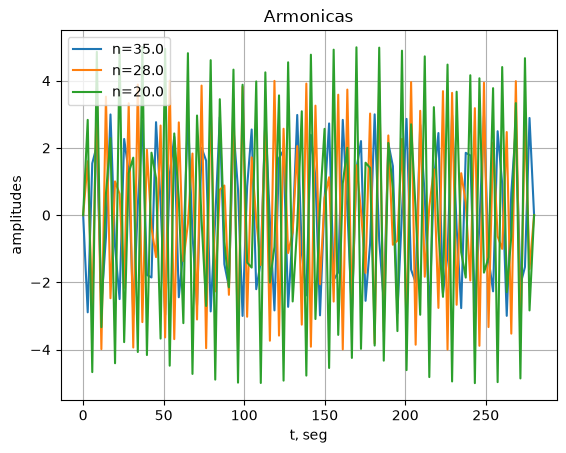

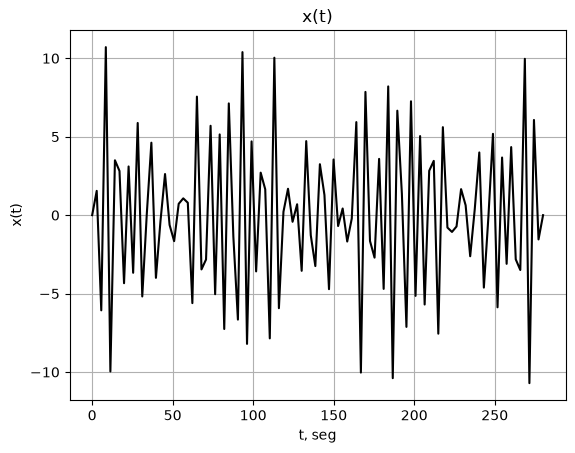

In [4]:
#Puede que necesite digitar dos veces shift-intro

import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

fig, g = plt.subplots() 
t = np.linspace(0, 2*T, 100)

for k in range(len(periodos)):
    g.plot(t, coeficientes[k]*np.sin(2*np.pi/periodos[k]*t), label="n={0}".format(armonicas[k]))
plt.xlabel('t, seg')
plt.ylabel('amplitudes')
plt.title('Armonicas')
plt.grid(True)
plt.legend()
plt.show()

s = [0]*100
for k in range(len(periodos)):
    t = np.linspace(0, 2*T, 100)
    sp = (coeficientes[k]*np.sin(2*np.pi/periodos[k]*t))
    s += sp
plt.plot(t, s, 'k')
plt.title('x(t)')
plt.xlabel('t, seg')
plt.ylabel('x(t)')
plt.grid(True)
plt.show()

#### Y su gráfica del espectro de amplitud.

<function matplotlib.pyplot.show(close=None, block=None)>

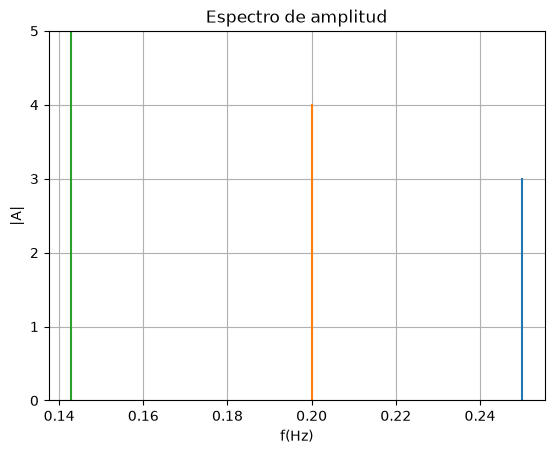

In [5]:
for i in range(len(coeficientes)):
    x = [[frecuencia[i], frecuencia[i]]]
    y = [[0, abs(coeficientes[i])]]
    plt.plot(x[0], y[0])
plt.title('Espectro de amplitud')
plt.xlabel('f(Hz)')
plt.ylabel('|A|')
plt.grid(True)
#plt.xlim(0,5)
plt.ylim(0,5)
plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

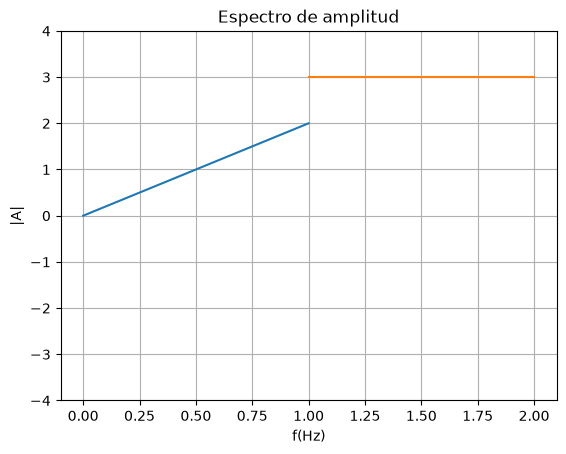

In [6]:
x = [[0, 1],[1, 2]]
y = [[0, 3],[2,3]]
plt.plot(x, y)
plt.title('Espectro de amplitud')
plt.xlabel('f(Hz)')
plt.ylabel('|A|')
plt.grid(True)
#plt.xlim(0,5)
plt.ylim(-4,4)
plt.show

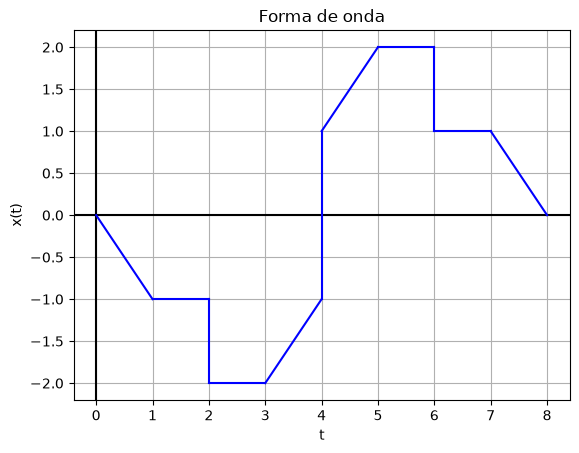

In [7]:
from pylab import*
import matplotlib.pyplot as plt
%matplotlib inline
data=[(0, 1), (0, -1), 'b',(1, 2), (-1, -1), 'b', (2, 2), (-1, -2), 'b', (2, 3), (-2, -2), 'b',
     (3, 4), (-2, -1), 'b', (4, 4), (-1, 1), 'b', (4, 5), (1, 2), 'b', (5, 6), (2, 2), 'b',
     (6, 6), (2, 1), 'b', (6, 7), (1, 1), 'b', (7, 8), (1, 0), 'b'] #(x1, x2), (y1, y2)
plt.title('Forma de onda')
plt.xlabel('t')
plt.ylabel('x(t)')
plt.grid(True)
axhline(y=0, color='k')
axvline(x=0, color='k')
#plt.xlim(0,5)
#plt.ylim(-4,4)
plt.plot(*data)

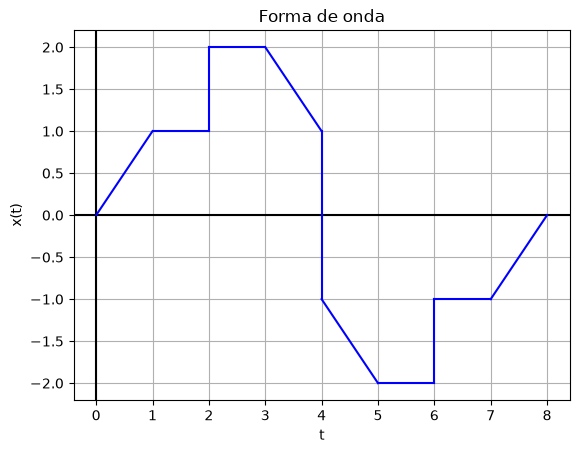

In [8]:
from pylab import*
import matplotlib.pyplot as plt
%matplotlib inline
data=[(0, 1), (0, 1), 'b',(1, 2), (1, 1), 'b', (2, 2), (1, 2), 'b', (2, 3), (2, 2), 'b',
     (3, 4), (2, 1), 'b', (4, 4), (1, -1), 'b', (4, 5), (-1, -2), 'b', (5, 6), (-2, -2), 'b',
     (6, 6), (-2, -1), 'b', (6, 7), (-1, -1), 'b', (7, 8), (-1, 0), 'b'] #(x1, x2), (y1, y2)
plt.title('Forma de onda')
plt.xlabel('t')
plt.ylabel('x(t)')
plt.grid(True)
axhline(y=0, color='k')
axvline(x=0, color='k')
#plt.xlim(0,5)
#plt.ylim(-4,4)
plt.plot(*data)

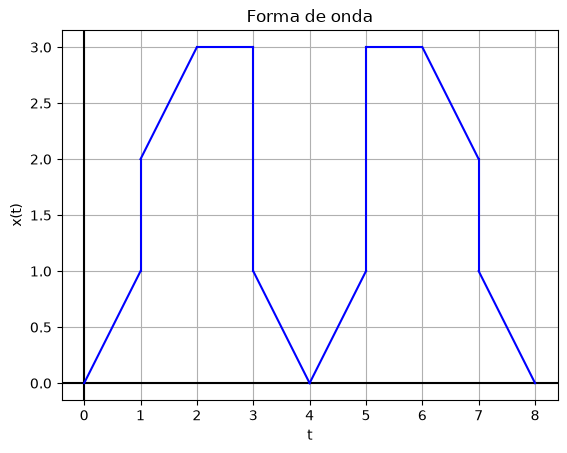

In [9]:
from pylab import*
import matplotlib.pyplot as plt
%matplotlib inline
data=[(0, 1), (0, 1), 'b', (1, 1), (1, 2), 'b', (1, 2), (2, 3), 'b',
     (2, 3), (3, 3), 'b', (3, 3), (3, 1), 'b', (3, 4), (1, 0), 'b', (4, 5), (0, 1), 'b',
     (5, 5), (1, 3), 'b', (5, 6), (3, 3), 'b', (6, 7), (3, 2), 'b', (7,7), (2,1), 'b',
     (7, 8), (1, 0), 'b'] #(x1, x2), (y1, y2)
plt.title('Forma de onda')
plt.xlabel('t')
plt.ylabel('x(t)')
plt.grid(True)
axhline(y=0, color='k')
axvline(x=0, color='k')
#plt.xlim(0,5)
#plt.ylim(-4,4)
plt.plot(*data)

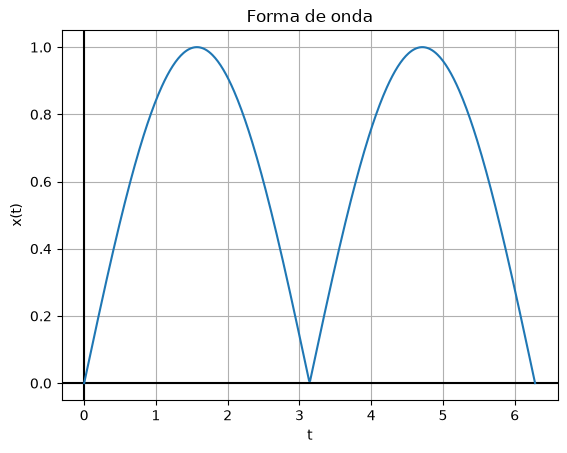

In [10]:
from pylab import*
import matplotlib.pyplot as plt
%matplotlib inline
x = linspace(0, 2*pi, 500)
plt.title('Forma de onda')
plt.xlabel('t')
plt.ylabel('x(t)')
plt.grid(True)
axhline(y=0, color='k')
axvline(x=0, color='k')
#plt.xlim(0,5)
#plt.ylim(-4,4)
plt.plot(x, abs(sin(x)))